# 01 · Exploratory Data Analysis — turkish-wikiNER

Bu notebook, modellemeden önce veri setinin dağılımını, dilbilimsel/yapısal özelliklerini ve kolay/zor/gürültülü yönlerini inceler.
Veri `src/download_data.py` ile `data/turkish-wikiNER/` altına indirilmiş olmalı.

In [1]:
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_from_disk

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

ds = load_from_disk(str(ROOT / "data" / "turkish-wikiNER"))
TAGS = ds["train"].features["tags"].feature.names
SPLITS = ["train", "validation", "test"]
pd.set_option("display.max_colwidth", 120)
ds

C:\Users\tasov\Desktop\ASELSAN Mulakat\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['tokens', 'tags'],
        num_rows: 17967
    })
    validation: Dataset({
        features: ['tokens', 'tags'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['tokens', 'tags'],
        num_rows: 1000
    })
})

In [2]:
def spans(tags):
    """IOB2 dizisinden (tip, başlangıç, bitiş) varlık aralıklarını çıkarır.
    Önünde B- olmayan I- etiketi yeni bir varlık başlatır (seqeval'in 'lenient' davranışı)."""
    out, cur = [], None
    for i, t in enumerate(tags + ["O"]):
        prefix, _, typ = t.partition("-")
        if cur and (prefix != "I" or typ != cur[0]):
            out.append((cur[0], cur[1], i)); cur = None
        if prefix == "B" or (prefix == "I" and cur is None):
            cur = (typ, i)
    return out

# Her split'i (cümle_id, tokens, tag string'leri, span'ler) olarak tek seferde hazırla
data = {}
for s in SPLITS:
    rows = []
    for i, ex in enumerate(ds[s]):
        tags = [TAGS[t] for t in ex["tags"]]
        rows.append({"id": i, "tokens": ex["tokens"], "tags": tags, "spans": spans(tags)})
    data[s] = rows

assert spans(["B-PERSON", "I-PERSON", "O", "I-GPE", "B-ORG"]) == [("PERSON", 0, 2), ("GPE", 3, 4), ("ORG", 4, 5)]

## 1. Özet istatistikler

In [3]:
summary = []
for s in SPLITS:
    rows = data[s]
    n_tok = sum(len(r["tokens"]) for r in rows)
    n_ent = sum(len(r["spans"]) for r in rows)
    summary.append({
        "split": s, "cümle": len(rows), "token": n_tok, "varlık": n_ent,
        "ort. cümle uzunluğu": round(n_tok / len(rows), 1),
        "varlık / cümle": round(n_ent / len(rows), 2),
        "varlıksız cümle %": round(100 * sum(not r["spans"] for r in rows) / len(rows), 1),
        "O olmayan token %": round(100 * sum(t != "O" for r in rows for t in r["tags"]) / n_tok, 1),
    })
pd.DataFrame(summary).set_index("split")

,cümle,token,varlık,ort. cümle uzunluğu,varlık / cümle,varlıksız cümle %,O olmayan token %
split,,,,,,,
train,17967,303443,51764,16.9,2.88,10.6,29.9
validation,1000,16658,2969,16.7,2.97,11.7,30.3
test,1000,17275,3016,17.3,3.02,10.4,30.8


## 2. Varlık tipi dağılımı (span seviyesinde)

In [4]:
ent_counts = pd.DataFrame({s: Counter(t for r in data[s] for t, _, _ in r["spans"]) for s in SPLITS}).fillna(0).astype(int)
ent_counts = ent_counts.sort_values("train", ascending=False)
ent_counts["train %"] = (100 * ent_counts["train"] / ent_counts["train"].sum()).round(2)
ent_counts

,train,validation,test,train %
PERSON,11492,641,654,22.20
GPE,9209,593,566,17.79
DATE,6245,335,343,12.06
ORG,4081,252,250,7.88
CARDINAL,3876,179,240,7.49
NORP,3636,175,212,7.02
WORK_OF_ART,2637,156,158,5.09
EVENT,2197,100,95,4.24
TITLE,2136,205,153,4.13
ORDINAL,1500,107,104,2.90


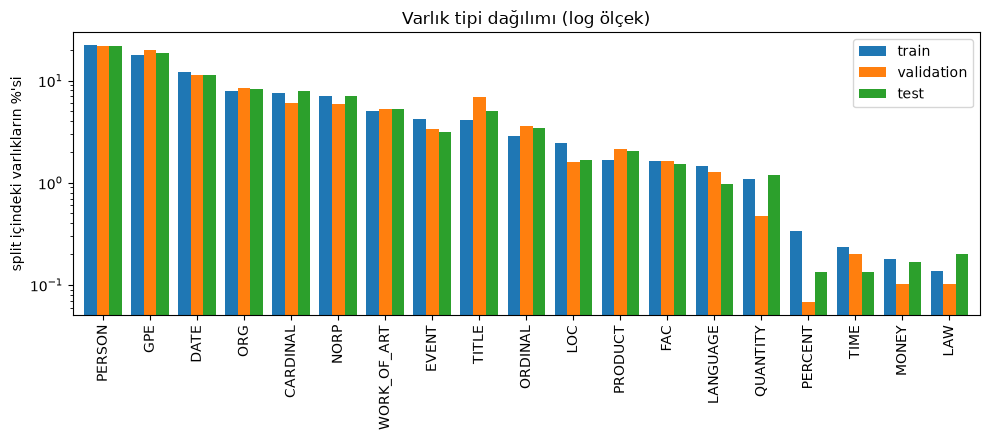

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
(ent_counts[SPLITS] / ent_counts[SPLITS].sum() * 100).plot.bar(ax=ax, width=0.8)
ax.set_ylabel("split içindeki varlıkların %'si"); ax.set_yscale("log")
ax.set_title("Varlık tipi dağılımı (log ölçek)")
plt.tight_layout(); plt.savefig(FIG / "entity_type_distribution.png", dpi=150); plt.show()

## 3. Uzunluk dağılımları

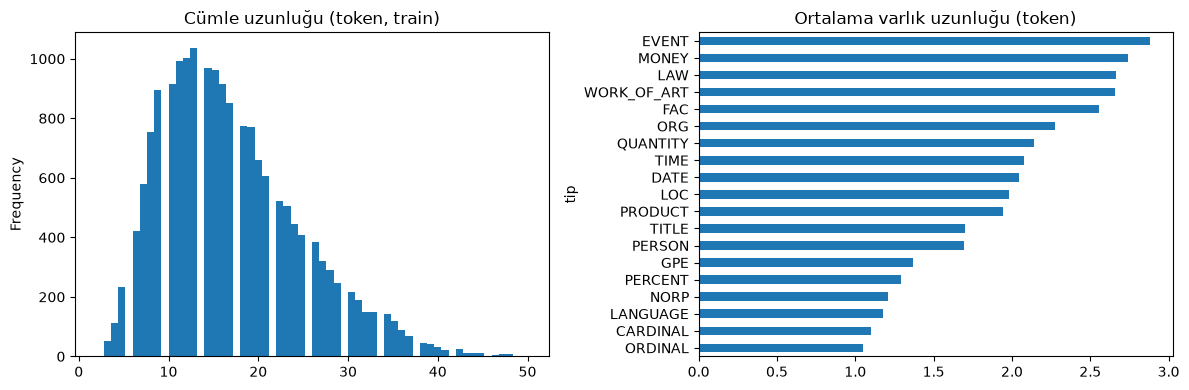

{'count': 17967.0, 'mean': 16.9, 'std': 7.7, 'min': 2.0, '25%': 11.0, '50%': 16.0, '75%': 21.0, 'max': 50.0}


In [6]:
sent_len = pd.Series([len(r["tokens"]) for r in data["train"]])
span_len = pd.DataFrame([(t, e - b) for r in data["train"] for t, b, e in r["spans"]], columns=["tip", "uzunluk"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sent_len.plot.hist(bins=60, ax=axes[0], title="Cümle uzunluğu (token, train)")
span_len.groupby("tip")["uzunluk"].mean().sort_values().plot.barh(ax=axes[1], title="Ortalama varlık uzunluğu (token)")
plt.tight_layout(); plt.savefig(FIG / "length_distributions.png", dpi=150); plt.show()
print(sent_len.describe().round(1).to_dict())

In [7]:
span_len.groupby("tip")["uzunluk"].describe()[["count", "mean", "50%", "max"]].sort_values("mean")

,count,mean,50%,max
tip,,,,
ORDINAL,1500.0,1.046667,1.0,3.0
CARDINAL,3876.0,1.101135,1.0,7.0
LANGUAGE,755.0,1.174834,1.0,6.0
NORP,3636.0,1.209846,1.0,9.0
PERCENT,176.0,1.289773,1.0,5.0
GPE,9209.0,1.369204,1.0,20.0
PERSON,11492.0,1.697181,2.0,13.0
TITLE,2136.0,1.698034,1.0,12.0
PRODUCT,865.0,1.944509,2.0,11.0


## 4. Dilbilimsel / yapısal özellikler

Türkçe eklemeli bir dil: özel isimlere gelen çekim ekleri kesme işaretiyle ayrılır (`Ankara'da`) ama token'a yapışık kalır.
Büyük harf güçlü bir sinyal ama cümle başında ve bazı sıradan kelimelerde de bulunur.

In [8]:
def token_profile(rows):
    feats = defaultdict(Counter)
    for r in rows:
        for i, (tok, tag) in enumerate(zip(r["tokens"], r["tags"])):
            grp = "O" if tag == "O" else tag.split("-")[1]
            feats[grp]["n"] += 1
            feats[grp]["büyük harfle başlar"] += tok[:1].isupper()
            feats[grp]["kesme işareti içerir"] += ("'" in tok or "’" in tok)
            feats[grp]["rakam içerir"] += any(c.isdigit() for c in tok)
            feats[grp]["cümle başı"] += i == 0
    df = pd.DataFrame(feats).T
    return (df.drop(columns="n").div(df["n"], axis=0) * 100).round(1).assign(n=df["n"]).sort_values("n", ascending=False)

token_profile(data["train"])

,büyük harfle başlar,kesme işareti içerir,rakam içerir,cümle başı,n
O,5.7,0.3,0.1,3.7,212721
PERSON,96.0,17.0,0.2,16.6,19504
DATE,16.8,14.2,62.5,13.9,12758
GPE,92.9,34.5,0.1,12.5,12609
ORG,90.5,14.0,1.6,9.2,9278
WORK_OF_ART,82.7,5.7,1.5,7.8,7017
EVENT,80.0,12.0,8.0,6.6,6330
NORP,90.5,7.7,0.3,10.1,4399
CARDINAL,2.9,3.7,56.7,4.0,4268
TITLE,41.8,1.7,0.5,5.3,3627


In [9]:
# Büyük harfle başlayan ama O etiketli, cümle başı olmayan token'lar: büyük harf sinyalinin 'yanlış pozitif' kaynağı
cap_O = Counter(tok for r in data["train"] for i, (tok, tag) in enumerate(zip(r["tokens"], r["tags"]))
                if tag == "O" and i > 0 and tok[:1].isupper())
pd.Series(cap_O).sort_values(ascending=False).head(25)

En        68
İyi       55
A         31
Bu        28
Dünya     27
B         19
C         17
Batı      17
DVD       17
Yeni      15
R&B       15
Film      15
DNA       15
R         14
O         14
TV        13
Yılın     12
Kuzey     11
Kadın     10
U         10
Ordusu    10
Büyük     10
Lie        9
St         9
İlk        9
dtype: int64

In [10]:
# Kesme işaretinden sonra gelen eklerin dağılımı (varlık token'larında)
suffixes = Counter(tok.replace("’", "'").split("'")[-1].lower()
                   for r in data["train"] for tok, tag in zip(r["tokens"], r["tags"])
                   if tag != "O" and ("'" in tok or "’" in tok))
print(f"{len(suffixes)} farklı ek, toplam {sum(suffixes.values())} kullanım")
pd.Series(suffixes).sort_values(ascending=False).head(25)

260 farklı ek, toplam 13531 kullanım


da      1509
de      1379
nın     1050
in       947
nin      881
ın       875
un       505
a        423
ya       397
te       393
nde      346
e        342
nda      289
dan      253
nun      251
daki     241
ye       226
den      210
i        192
ne       178
ı        166
ta       163
li       145
yı       141
na       138
dtype: int64

## 5. Zorluk analizi

- **Görülmemiş varlıklar:** test'teki varlık yüzey biçimlerinin ne kadarı train'de hiç geçmiyor? Ezberleyen modeller burada düşer.
- **Tip belirsizliği:** aynı yüzey biçimi farklı tiplerle etiketlenmiş mi? (ör. bir ülke adı GPE mi, NORP mu, ORG mu)

In [11]:
def surfaces(rows):
    return [(" ".join(r["tokens"][b:e]), t) for r in rows for t, b, e in r["spans"]]

train_surf = Counter(surfaces(data["train"]))
train_forms = {f for f, _ in train_surf}
test_surf = surfaces(data["test"])

unseen = pd.DataFrame([(t, f not in train_forms) for f, t in test_surf], columns=["tip", "görülmemiş"])
print(f"Test varlıklarının %{100 * unseen['görülmemiş'].mean():.1f}'i train'de hiç geçmiyor")
unseen.groupby("tip")["görülmemiş"].agg(["count", "mean"]).rename(columns={"mean": "görülmemiş oranı"}).round(2).sort_values("görülmemiş oranı", ascending=False)

Test varlıklarının %60.2'i train'de hiç geçmiyor


,count,görülmemiş oranı
tip,,
MONEY,5,1.00
PERCENT,4,1.00
QUANTITY,36,0.94
FAC,46,0.91
WORK_OF_ART,158,0.89
EVENT,95,0.87
PRODUCT,61,0.84
LAW,6,0.83
ORG,250,0.81


In [12]:
# Aynı yüzey biçiminin birden fazla tiple etiketlenmesi
by_form = defaultdict(Counter)
for (f, t), c in train_surf.items():
    by_form[f][t] += c
ambig = {f: dict(c) for f, c in by_form.items() if len(c) > 1}
print(f"{len(ambig)} / {len(by_form)} farklı yüzey biçimi birden fazla tiple etiketlenmiş")
pd.Series({f: c for f, c in ambig.items()}).loc[sorted(ambig, key=lambda f: -sum(ambig[f].values()))[:25]]

625 / 34592 farklı yüzey biçimi birden fazla tiple etiketlenmiş


bir                                       {'CARDINAL': 615, 'NORP': 1, 'ORDINAL': 2}
ilk            {'ORDINAL': 361, 'TITLE': 1, 'QUANTITY': 1, 'CARDINAL': 4, 'DATE': 1}
iki                                                  {'CARDINAL': 318, 'ORDINAL': 2}
Türk                                                        {'NORP': 175, 'DATE': 1}
Alman                                {'NORP': 131, 'PERSON': 1, 'GPE': 4, 'DATE': 1}
İngiliz                                       {'NORP': 131, 'LANGUAGE': 1, 'GPE': 4}
Fransız                                                      {'NORP': 114, 'GPE': 1}
ABD'li                                                       {'NORP': 105, 'GPE': 2}
1                                                    {'CARDINAL': 104, 'ORDINAL': 1}
3                                                       {'CARDINAL': 103, 'DATE': 1}
ABD                                               {'GPE': 89, 'NORP': 11, 'DATE': 1}
Türkiye'de                                                  {'GPE

In [13]:
# Hangi tip çiftleri en çok karışıyor?
pairs = Counter()
for c in ambig.values():
    ts = sorted(c)
    pairs.update((a, b) for i, a in enumerate(ts) for b in ts[i + 1:])
pd.Series(pairs).sort_values(ascending=False).head(15)

GPE       NORP           118
          LOC             76
          ORG             65
PERSON    WORK_OF_ART     50
GPE       PERSON          37
CARDINAL  DATE            34
ORG       PERSON          32
EVENT     ORG             30
NORP      ORG             24
ORG       PRODUCT         20
NORP      PERSON          17
CARDINAL  ORDINAL         14
ORG       WORK_OF_ART     12
FAC       GPE             11
LANGUAGE  NORP            11
dtype: int64

## 6. Gürültü ve tutarlılık kontrolleri

- Geçersiz IOB geçişleri (önünde aynı tipten B-/I- olmayan I-)
- Split'ler arası tekrar eden cümleler (veri sızıntısı)
- Etiketlenmemiş kalmış olası varlıklar: train'de çoğunlukla varlık olan bir yüzey biçiminin O olarak geçtiği yerler

In [14]:
invalid = []
for s in SPLITS:
    for r in data[s]:
        prev = "O"
        for i, t in enumerate(r["tags"]):
            if t.startswith("I-") and prev[2:] != t[2:]:
                invalid.append((s, r["id"], i, prev, t))
            prev = t
print(f"Geçersiz I- geçişi sayısı: {len(invalid)}")
pd.DataFrame(invalid, columns=["split", "cümle", "pozisyon", "önceki", "etiket"]).head(10)

Geçersiz I- geçişi sayısı: 0


,split,cümle,pozisyon,önceki,etiket


In [15]:
sent_key = {s: Counter(" ".join(r["tokens"]) for r in data[s]) for s in SPLITS}
print("train içi tekrar eden cümle:", sum(c - 1 for c in sent_key["train"].values() if c > 1))
for s in ["validation", "test"]:
    print(f"{s} ∩ train ortak cümle:", len(set(sent_key[s]) & set(sent_key["train"])))

train içi tekrar eden cümle: 0
validation ∩ train ortak cümle: 0
test ∩ train ortak cümle: 0


In [16]:
# Tek token'lık varlık biçimleri train'de >=5 kez varlık olarak geçip aynı zamanda O olarak da geçiyorsa: olası eksik etiket ya da gerçek belirsizlik
single = Counter(f for (f, t), c in train_surf.items() for _ in range(c) if " " not in f)
as_O = Counter(tok for r in data["train"] for tok, tag in zip(r["tokens"], r["tags"]) if tag == "O")
miss = pd.DataFrame([(f, single[f], as_O[f], round(as_O[f] / (single[f] + as_O[f]), 2))
                     for f in single if single[f] >= 5 and as_O[f] > 0],
                    columns=["token", "varlık olarak", "O olarak", "O oranı"]).sort_values("O olarak", ascending=False)
print(f"{len(miss)} biçim hem varlık hem O olarak etiketlenmiş")
miss.head(25)

171 biçim hem varlık hem O olarak etiketlenmiş


,token,varlık olarak,O olarak,O oranı
17,bir,618,3986,0.87
1,ilk,368,541,0.60
123,son,10,200,0.95
94,biri,12,192,0.94
136,tek,10,153,0.94
29,oyuncu,25,103,0.80
60,futbolcu,27,97,0.78
10,İlk,67,83,0.55
111,Bir,22,83,0.79
36,yazar,25,52,0.68


In [17]:
def show(row, highlight=None):
    """Cümleyi varlıkları [metin|TİP] biçiminde işaretleyerek yazdırır."""
    toks, out, i = row["tokens"], [], 0
    for t, b, e in row["spans"]:
        out += toks[i:b] + [f"[{' '.join(toks[b:e])}|{t}]"]; i = e
    return " ".join(out + toks[i:])

# Örnek: en çok 'O' olarak da geçen varlık biçimini içeren birkaç cümle
tok = miss.iloc[0]["token"]
for r in [r for r in data["train"] if tok in r["tokens"]][:6]:
    print("-", show(r))

- " Macera edebiyatın [ilk|ORDINAL] günlerinden beridir yaygın bir tema olmuştur .
- [11 Temmuz 1927 tarihinde|DATE] [Filistin'de|GPE] [meydana gelen depremde|EVENT] önemli ölçüde hasar gören [Kubbet üs Sahra|FAC] , [Ürdün|GPE] , diğer [Arap ülkeleri|GPE] ve [Türkiye'nin|GPE] katkıları ile esaslı bir şekilde tamir edildi .
- [Profesör|TITLE] [Bosco|PERSON] , eğitimli pirelerini içinde taşıdığı bir kutuyla beraber izbe bir motele gelir .
- [Ardenler'in|GPE] büyük bir bölümü yoğun ormanlarla , zaman zaman [650 m.yi|QUANTITY] bulan ortalama [350 500 m.|QUANTITY] yüksekliğinde tepelerle kaplıdır .
- [İran'daki|GPE] [Kürtler|NORP] ve özellikle [Irak'taki|GPE] [Kürtler|NORP] arasında önemli bir etkileşim olmuş , bu da edebiyat ve dil alanında kendisini göstermiştir .
- Elektrik akımı bir manyetik alan meydana getirir .


## 7. Nadir tiplerden örnekler

In [18]:
rare = ent_counts.index[-6:]
for t in rare:
    ex = [r for r in data["train"] if any(s[0] == t for s in r["spans"])][:2]
    print(f"### {t}")
    for r in ex:
        print("  -", show(r))

### LANGUAGE
  - [Refrain Lys Assia|PERSON] tarafından söylenen ve [1956 Eurovision Şarkı Yarışması'nı|EVENT] yani [ilk Eurovisionu|EVENT] kazanan [Fransızca|LANGUAGE] şarkı .
  - Sözleri [George Moustaki'ye|PERSON] , müziği [Marqueritte Monnot'ya|PERSON] ait , [1959 tarihli|DATE] [Fransızca|LANGUAGE] şarkı .
### QUANTITY
  - [Ardenler'in|GPE] büyük bir bölümü yoğun ormanlarla , zaman zaman [650 m.yi|QUANTITY] bulan ortalama [350 500 m.|QUANTITY] yüksekliğinde tepelerle kaplıdır .
  - Urmiye semenderi , Salamandridae familyasından [Türkiye|GPE] , [Irak|GPE] ve [İran'da|GPE] yaşayan , [19 cm|QUANTITY] boyunda bir semender türü .
### PERCENT
  - [Mayıs Haziran 2007|DATE] yılında şirket hisselerinin [%20|PERCENT] si [ESAS Holding|ORG] ( [Pegasus Havayollarının|ORG] da sahibi ) tarafından satın alınarak yönetim değişikliği yapıldı .
  - Alanı [443684.71 km|QUANTITY] olan bölgenin nüfusu [11627 kişi|CARDINAL] olup bunun [% 90 ı|PERCENT] [İnuit Eskimosudur|NORP] .
### TIME
  - [İlk|ORDINAL] 

### LAW
  - [5 Temmuz 1995'te|DATE] uygulamaya giren [Ermenistan Anayasası|LAW] ile , [Erivan'a|GPE] marz ( bölge ) statüsü verildi .
  - [I. Peloponez Savaşı|EVENT] , [Atina|GPE] ile [Sparta|GPE] arasında , [Otuz Yıl Barışı|LAW] olarak bilinen bir barış antlaşmasıyla sona erdirilmiştir .


## 8. Gözlemler

> Bu bölümü çıktılara bakarak kendi yorumlarınla doldur: hangi sınıflar kolay/zor, hangi gürültüler var, bunlar baseline ve model seçimlerini nasıl etkiliyor.